# Punto 4 · Comparación con redes genéricas
**Red global del comercio de automóviles (UN Comtrade HS 8703, 2023)** · Grupo 4 · CD.30 Redes Complejas, ITBA

Este notebook responde una pregunta en dos pasos.

1. **Slide 9.** ¿La red real se parece a una red *al azar*? Comparamos contra dos modelos nulos: Erdős–Rényi y Configuración.
2. **Slide 10.** Si no se parece, ¿qué falta? Probamos dos modelos de comercio de la Clase #4B: **Fitness** y **Gravedad**.

**Idea central para exponer:** un modelo nulo no busca acertar. Busca ser una vara de medir. Si la red real se aleja mucho del modelo (|z| grande), hay un mecanismo que el modelo no captura.

## 0. Librerías y estilo

In [31]:
import json, numpy as np, pandas as pd, networkx as nx
import matplotlib.pyplot as plt
from networkx.algorithms import community as nc
from scipy.stats import rankdata, spearmanr
from scipy.optimize import brentq

SEMILLA = 42
rng = np.random.default_rng(SEMILLA)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .25, "font.size": 11})
REAL, ER, CFG = "#D9480F", "#868E96", "#1C7ED6"   # real = naranja, ER = gris, Configuración = azul
RES = {}   # acá guardamos los números que van a las slides

# --- Carpeta de gráficos y buscador de datos (agregado) ---
import os, urllib.request
from pathlib import Path
os.makedirs("figs", exist_ok=True)          # los gráficos se guardan acá; se crea sola

REPO_RAW = "https://raw.githubusercontent.com/LhermannSauer/redes-complejas/tree/main/data/"
def abrir(nombre):
    """Busca data/<nombre> en la carpeta actual y en las superiores. Si no está, lo baja del repo en GitHub."""
    for base in [Path.cwd(), *Path.cwd().parents]:
        for sub in ("data", "."):
            p = base / sub / nombre
            if p.exists(): return p
    return urllib.request.urlopen(REPO_RAW + nombre)


## 1. La red real
Cargamos el grafo de 2023 y nos quedamos con las aristas de **USD 5 millones o más**. Ese filtro elimina ruido y conserva casi todo el valor.

In [32]:
REPO_RAW = "https://raw.githubusercontent.com/LhermannSauer/redes-complejas/main/data/"

G = nx.read_graphml(abrir("hs8703_2023.graphml.xml"))

H = nx.DiGraph((u, v, d) for u, v, d in G.edges(data=True) if d["weight"] >= 5e6)   # red dirigida y pesada
U = H.to_undirected()                                                                # versión no dirigida

N, L = H.number_of_nodes(), H.number_of_edges()
tot = sum(d["weight"] for *_, d in G.edges(data=True)); ret = sum(d["weight"] for *_, d in H.edges(data=True))
print(f"Nodos N = {N} | Aristas dirigidas L = {L} | Aristas no dirigidas = {U.number_of_edges()}")
print(f"Valor retenido: {ret/tot:.1%} (USD {ret/1e9:,.1f} mil millones)")
print(f"Países que exportan (k_out > 0): {sum(1 for _, d in H.out_degree() if d > 0)} | sin exportar: {sum(1 for _, d in H.out_degree() if d == 0)}")

Nodos N = 193 | Aristas dirigidas L = 2140 | Aristas no dirigidas = 1785
Valor retenido: 99.7% (USD 928.7 mil millones)
Países que exportan (k_out > 0): 69 | sin exportar: 124


## 2. Parte A · Modelos nulos (slide 9)

Un **modelo nulo** genera redes al azar conservando *algo* de la red real. Elegimos qué conservar.

| Modelo | Qué conserva | Pregunta que responde |
|---|---|---|
| **Erdős–Rényi (ER)** | Solo N y L | ¿Alcanza el azar puro? |
| **Configuración** | Los grados de entrada y salida de cada país | ¿Alcanzan los hubs para explicar la estructura? |

**Cómo generamos cada modelo.**
- **ER:** sorteamos al azar N nodos y L aristas. Para el grado usamos la versión dirigida. Para clustering, distancia y modularidad usamos ER no dirigido con las mismas aristas únicas que la red real (así comparamos lo mismo con lo mismo).
- **Configuración:** partimos de la red real y *reordenamos las aristas* con intercambios (si A→B y C→D, pasan a A→D y C→B). Cada país conserva **exactamente** su grado de entrada y de salida.

**Método.** Generamos 100 redes de cada modelo. Medimos la métrica en cada una. Comparamos con la red real mediante el **z-score**:

$$ z = \frac{X_{real} - \mu_{modelo}}{\sigma_{modelo}} $$

Si $|z| > 2$, la red real es *distinta de lo esperado*.

In [33]:
def metricas(Gu, kmax_out):
    """Métricas sobre la versión no dirigida. La distancia se mide en la componente gigante."""
    gig = Gu.subgraph(max(nx.connected_components(Gu), key=len))
    return {"C": nx.average_clustering(Gu),
            "d": nx.average_shortest_path_length(gig),
            "kmax_out": kmax_out,
            "Q": max(nc.modularity(Gu, nc.louvain_communities(Gu, seed=k)) for k in range(5))}   # Louvain es estocástico: mejor de 5 corridas

Lu = U.number_of_edges()
real = metricas(U, max(d for _, d in H.out_degree()))

R = 100
filas_er, filas_cfg = [], []
for s in range(R):
    # Erdős–Rényi: mismos N y L. Dirigido para el grado; no dirigido (mismas aristas únicas) para C, d y Q.
    e_d = nx.gnm_random_graph(N, L, directed=True, seed=s)
    e_u = nx.gnm_random_graph(N, Lu, seed=s)
    filas_er.append(metricas(e_u, max(d for _, d in e_d.out_degree())))
    # Configuración: mismos grados EXACTOS de entrada y salida. Se reordenan las aristas con intercambios (u→v, x→y ⇒ u→y, x→v).
    c = nx.directed_edge_swap(H.copy(), nswap=5*L, max_tries=500*L, seed=s)
    filas_cfg.append(metricas(c.to_undirected(), max(d for _, d in c.out_degree())))
er, cfg = pd.DataFrame(filas_er), pd.DataFrame(filas_cfg)

tabla = pd.DataFrame({"Real": real,
                      "ER (media)": er.mean(), "ER (desvío)": er.std(),
                      "Config (media)": cfg.mean(), "Config (desvío)": cfg.std()})
tabla["z vs ER"] = (tabla["Real"] - tabla["ER (media)"]) / tabla["ER (desvío)"]
tabla["z vs Config"] = (tabla["Real"] - tabla["Config (media)"]) / tabla["Config (desvío)"].replace(0, np.nan)
tabla.round(3)

,Real,ER (media),ER (desvío),Config (media),Config (desvío),z vs ER,z vs Config
C,0.708,0.097,0.003,0.696,0.005,209.986,2.288
d,2.072,2.056,0.003,2.047,0.008,5.390,3.124
kmax_out,139.000,20.790,1.653,139.000,0.000,71.502,NaN
Q,0.263,0.194,0.004,0.312,0.049,18.048,-0.997


In [34]:
RES["A"] = {k: {"real": float(real[k]),
                "er_mu": float(er[k].mean()), "er_sd": float(er[k].std()),
                "cfg_mu": float(cfg[k].mean()), "cfg_sd": float(cfg[k].std()),
                "z_er": float((real[k]-er[k].mean())/er[k].std()) if er[k].std() > 0 else None,
                "z_cfg": float((real[k]-cfg[k].mean())/cfg[k].std()) if cfg[k].std() > 0 else None} for k in real}
RES["A"]["R"] = R; RES["A"]["Lu"] = Lu

**Cómo leer la tabla (para decirlo en voz alta).**
- **Clustering ⟨C⟩.** ER da un valor muy bajo (el azar no genera triángulos). Configuración ya se acerca mucho. Los triángulos nacen del *núcleo de hubs*: si los hubs se conectan entre sí, sus vecinos también.
- **Distancia ⟨d⟩.** Las tres redes son de mundo pequeño (≈ 2 pasos). La distancia corta no distingue a la red real del azar.
- **Grado máximo.** ER no genera hubs. La red real tiene un país que exporta a 139 destinos.

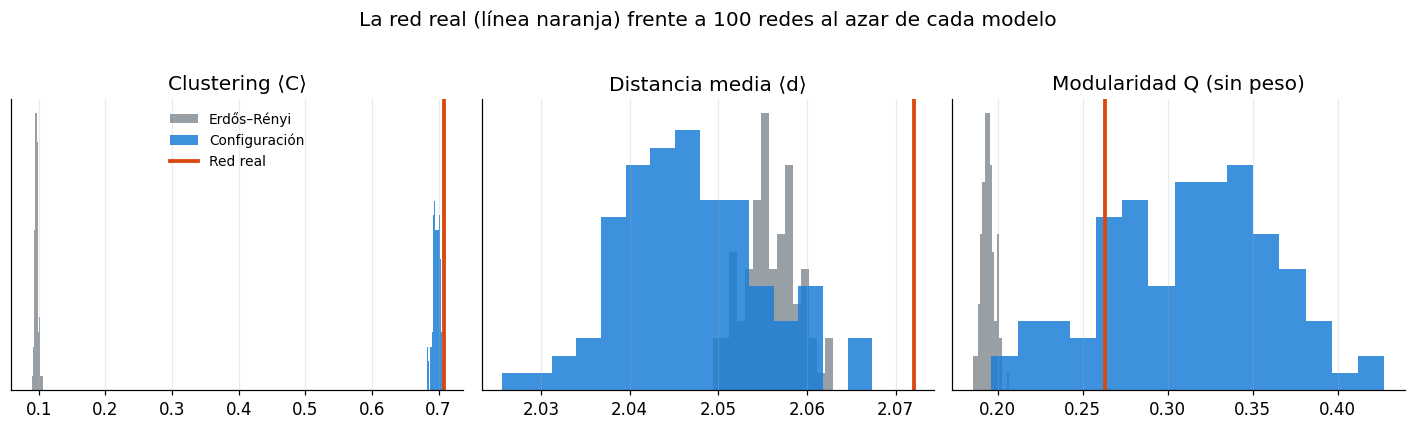

In [35]:
fig, axs = plt.subplots(1, 3, figsize=(13, 3.8))
for ax, (k, titulo) in zip(axs, [("C", "Clustering ⟨C⟩"), ("d", "Distancia media ⟨d⟩"), ("Q", "Modularidad Q (sin peso)")]):
    ax.hist(er[k], bins=15, color=ER, alpha=.85, label="Erdős–Rényi")
    ax.hist(cfg[k], bins=15, color=CFG, alpha=.85, label="Configuración")
    ax.axvline(real[k], color=REAL, lw=2.5, label="Red real")
    ax.set_title(titulo); ax.set_yticks([])
axs[0].legend(frameon=False, fontsize=9, loc="upper center")
fig.suptitle("La red real (línea naranja) frente a 100 redes al azar de cada modelo", y=1.02)
plt.tight_layout(); plt.savefig("figs/A1_modelos_nulos.png", dpi=200, bbox_inches="tight"); plt.show()

### Distribución de grados: ¿hay hubs?
La **CCDF** $P(K \ge k)$ muestra qué fracción de países tiene al menos $k$ destinos. En escala log-log una cola larga indica hubs.

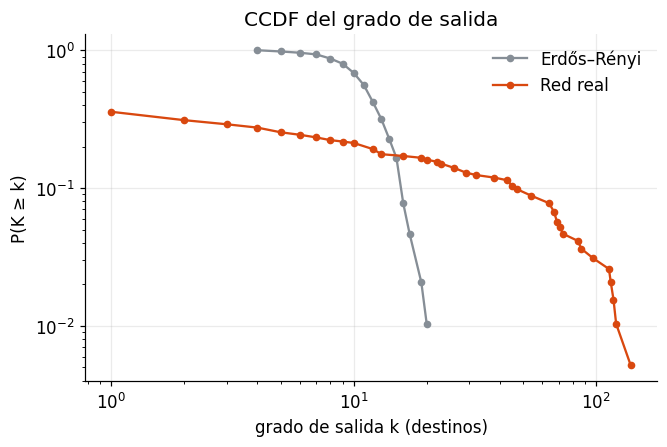

Grado máximo real: 139 | ER (réplica 0): 20 | 124 países (64%) tienen k_out = 0


In [37]:
def ccdf(ks):
    ks = np.sort(np.array(ks)); x = np.unique(ks[ks > 0])
    return x, np.array([(ks >= v).mean() for v in x])

k_real = [d for _, d in H.out_degree()]
k_er   = [d for _, d in nx.gnm_random_graph(N, L, directed=True, seed=0).out_degree()]
fig, ax = plt.subplots(figsize=(6.2, 4.2))
for ks, col, lab in [(k_er, ER, "Erdős–Rényi"), (k_real, REAL, "Red real")]:
    x, y = ccdf(ks); ax.loglog(x, y, "o-", color=col, ms=4, label=lab)
ax.set(xlabel="grado de salida k (destinos)", ylabel="P(K ≥ k)", title="CCDF del grado de salida")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig("figs/A2_ccdf.png", dpi=200); plt.show()
print(f"Grado máximo real: {max(k_real)} | ER (réplica 0): {max(k_er)} | {sum(1 for k in k_real if k==0)} países ({np.mean(np.array(k_real)==0):.0%}) tienen k_out = 0")
RES["A"]["pct_kout0"] = float(np.mean(np.array(k_real) == 0)); RES["A"]["n_kout0"] = int(sum(1 for k in k_real if k == 0))

### Conclusión de la Parte A
- ER **falla**: no explica ni los hubs ni los triángulos.
- Configuración **explica casi todo el clustering**. Con solo conocer los grados reproduce la estructura de triángulos.
- Pero estos modelos ven una red **binaria** (hay arista o no). No saben nada del **monto en dólares** ni del **tamaño de cada economía**. De ahí la Parte B.

## 3. Parte B · Datos externos: PBI y distancias

Para Fitness y Gravedad necesitamos dos datos por país.

- **PBI 2023 en USD corrientes**: Banco Mundial, indicador `NY.GDP.MKTP.CD` (API pública sin autenticación).
- **Distancia entre países**: calculamos la **distancia de círculo máximo (haversine)** entre las **capitales**. Usamos latitud y longitud de la API de países del Banco Mundial.

*Nota metodológica.* CEPII GeoDist usa distancias ponderadas por población de ciudades grandes. La distancia entre capitales es una aproximación estándar. Para países enormes (EE. UU., Rusia, China, Brasil) puede errar por cientos de km.

In [38]:
gdp = pd.read_csv(abrir("gdp_2023.csv")).dropna(subset=["pib_usd"]).set_index("iso3")["pib_usd"]
cap = pd.read_csv(abrir("capitales.csv")).set_index("iso3")

def haversine(lat1, lon1, lat2, lon2, R=6371.0):
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2-p1)/2)**2 + np.cos(p1)*np.cos(p2)*np.sin(np.radians(lon2-lon1)/2)**2
    return 2*R*np.arcsin(np.sqrt(a))

V = [v for v in H.nodes() if v in gdp.index and v in cap.index]        # países con ambos datos
falt = sorted(set(H.nodes()) - set(V))
print(f"Países con PBI y coordenadas: {len(V)} de {N}. Sin datos: {falt}")
print(f"Valor comercial cubierto: {sum(d['weight'] for u,v,d in H.edges(data=True) if u in V and v in V)/ret:.1%}")

idx = {v: i for i, v in enumerate(V)}
x = np.array([gdp[v] for v in V]) / 1e12                       # PBI en billones de USD
lat = np.array([cap.loc[v, "lat"] for v in V]); lon = np.array([cap.loc[v, "lon"] for v in V])
D = haversine(lat[:, None], lon[:, None], lat[None, :], lon[None, :])   # matriz de distancias en km
print(f"Distancia Buenos Aires–Brasilia: {D[idx['ARG'], idx['BRA']]:,.0f} km | Berlín–Tokio: {D[idx['DEU'], idx['JPN']]:,.0f} km")

A = np.zeros((len(V), len(V)), bool); W = np.zeros((len(V), len(V)))
for u, v, d in H.edges(data=True):
    if u in idx and v in idx: A[idx[u], idx[v]] = True; W[idx[u], idx[v]] = d["weight"]
kout, kin = A.sum(1), A.sum(0)
RES["B_datos"] = {"n_V": len(V), "N": N, "L_V": int(A.sum()), "falt": falt}

Países con PBI y coordenadas: 182 de 193. Sin datos: ['CUB', 'CUW', 'GIB', 'GUM', 'MNP', 'PSE', 'SSD', 'SXM', 'SYR', 'VGB', 'YEM']
Valor comercial cubierto: 99.9%
Distancia Buenos Aires–Brasilia: 2,341 km | Berlín–Tokio: 8,921 km


## 4. Modelo de **Fitness** (Garlaschelli y Loffredo, 2004)

**Idea.** Cada país tiene un *fitness* $x_i$: su PBI. Dos países grandes tienen más chances de comerciar. La probabilidad de que $i$ le venda a $j$ es:

$$ p_{ij} = \frac{z\, x_i x_j}{1 + z\, x_i x_j} $$

El parámetro $z$ es **uno solo**. Lo elegimos para que el número esperado de aristas $\sum_{ij} p_{ij}$ sea igual al observado ($L$).

**Qué aprendemos.** El modelo no ve la red, solo el PBI. Si predice bien quién le vende a quién, el tamaño económico explica la topología.

*Decisión de diseño.* Casi dos tercios de los países nunca figuran como exportadores. Que un país no exporte autos no depende de su PBI sino de si tiene industria automotriz. Por eso ajustamos el modelo para **exportadores potenciales** (los países que sí exportan) y aparte para **todos**.

In [39]:
def fitness(x, A, fuentes):
    """p_ij = z x_i x_j / (1 + z x_i x_j) con z elegido para igualar el número de aristas observado."""
    n = len(x); M = np.outer(x, x)
    mask = np.zeros((n, n), bool); mask[fuentes, :] = True; np.fill_diagonal(mask, False)
    L_obs = (A & mask).sum()
    f = lambda lz: (np.exp(lz)*M[mask] / (1 + np.exp(lz)*M[mask])).sum() - L_obs
    z = np.exp(brentq(f, -30, 30))
    P = np.where(mask, z*M/(1 + z*M), 0.0)
    return z, P, mask

def auc(score, y):
    """Probabilidad de que una arista real tenga mayor score que un par sin arista (0,5 = azar)."""
    r = rankdata(score); n1 = y.sum(); n0 = (~y).sum()
    return (r[y].sum() - n1*(n1+1)/2) / (n1*n0)

esexp = kout > 0
out = {}
for nombre, fuentes in [("Todos los países", np.arange(len(V))), ("Solo exportadores", np.where(esexp)[0])]:
    z, P, mask = fitness(x, A, fuentes)
    y = A[mask]
    kk = np.outer(kout, kin)[mask].astype(float)          # benchmark: producto de grados (≈ Configuración)
    out[nombre] = {"z": z, "pares": int(mask.sum()), "E_L": float(P.sum()), "L_obs": int(y.sum()),
                   "AUC_fitness": auc(P[mask], y), "AUC_grados": auc(kk, y), "AUC_dist": auc(-D[mask], y),
                   "rho_kout": spearmanr(P.sum(1)[fuentes], kout[fuentes])[0],
                   "rho_kin": spearmanr(P.sum(0), kin)[0]}
pd.DataFrame(out).T.round(3)

,z,pares,E_L,L_obs,AUC_fitness,AUC_grados,AUC_dist,rho_kout,rho_kin
Todos los países,1.262,32942.0,2106.0,2106.0,0.901,0.977,0.663,0.690,0.802
Solo exportadores,2.249,12489.0,2106.0,2106.0,0.829,0.931,0.656,0.638,0.802


In [40]:
# ¿Cuánto del "fitness esperado" cae en países que nunca exportan autos?
z_all, P_all, mask_all = fitness(x, A, np.arange(len(V)))
share_no_exp = P_all[~esexp, :].sum() / P_all.sum()
auc_exp = auc(x, esexp)      # ¿el PBI ordena bien quién es exportador?
print(f"Países que nunca exportan: {(~esexp).sum()} de {len(V)}. Fitness (todos) les asigna {share_no_exp:.0%} de las aristas esperadas; en la red real tienen 0%.")
print(f"AUC del PBI para predecir quién es exportador: {auc_exp:.2f}")
RES["B_exportadores"] = {"share_esperado_no_exportadores": float(share_no_exp), "auc_pbi_exportador": float(auc_exp), "n_no_exp": int((~esexp).sum())}

Países que nunca exportan: 113 de 182. Fitness (todos) les asigna 24% de las aristas esperadas; en la red real tienen 0%.
AUC del PBI para predecir quién es exportador: 0.88


**Cómo leer la tabla.**
- **AUC** mide qué tan bien un puntaje ordena los pares: ¿asigna más puntaje a los pares que sí comercian? 0,5 = azar (ER), 1 = perfecto.
- **AUC_fitness**: usa solo el PBI. **AUC_grados**: usa el producto de grados (lo que sabe Configuración). **AUC_dist**: usa solo cercanía.
- **rho**: correlación de Spearman entre el grado esperado por el modelo y el observado.

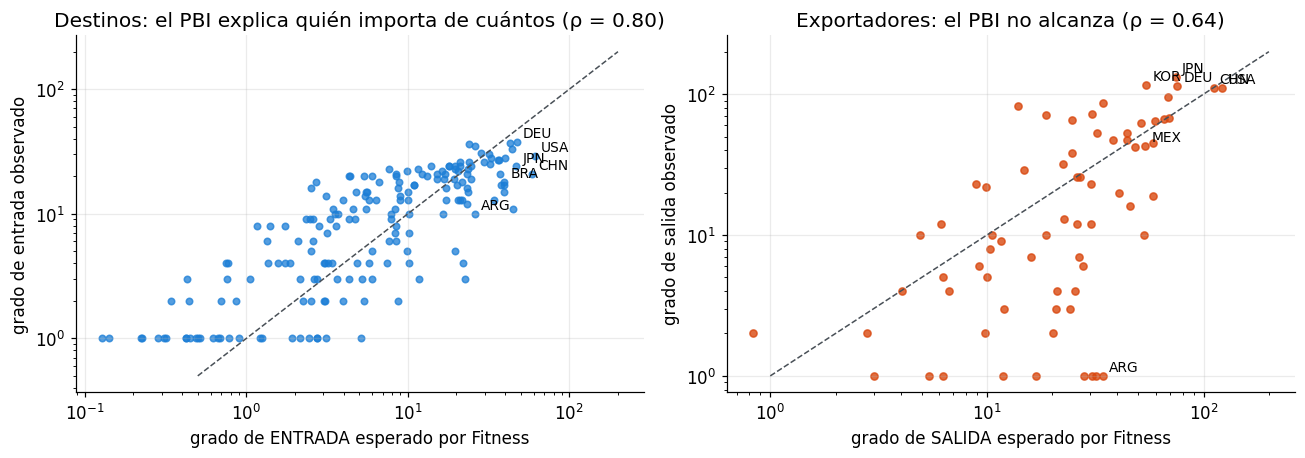

In [41]:
RES["B_fitness"] = out
z, P, mask = fitness(x, A, np.where(esexp)[0])
fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))

# (a) grado de entrada esperado vs observado
ax = axs[0]; xe, yo = P.sum(0), kin
ax.scatter(xe, yo, s=18, color=CFG, alpha=.75)
lim = [0.5, 200]; ax.plot(lim, lim, color="#495057", lw=1, ls="--")
ax.set(xscale="log", yscale="log", xlabel="grado de ENTRADA esperado por Fitness", ylabel="grado de entrada observado",
       title=f"Destinos: el PBI explica quién importa de cuántos (ρ = {out['Solo exportadores']['rho_kin']:.2f})")
for iso in ["USA", "DEU", "CHN", "ARG", "BRA", "JPN"]:
    if iso in idx: ax.annotate(iso, (xe[idx[iso]], yo[idx[iso]]), fontsize=9, xytext=(4, 3), textcoords="offset points")

# (b) grado de salida esperado vs observado (solo exportadores)
ax = axs[1]; f = np.where(esexp)[0]; xe, yo = P.sum(1)[f], kout[f]
ax.scatter(xe, yo, s=22, color=REAL, alpha=.8)
ax.plot([1, 200], [1, 200], color="#495057", lw=1, ls="--")
ax.set(xscale="log", yscale="log", xlabel="grado de SALIDA esperado por Fitness", ylabel="grado de salida observado",
       title=f"Exportadores: el PBI no alcanza (ρ = {out['Solo exportadores']['rho_kout']:.2f})")
for iso in ["DEU", "JPN", "CHN", "KOR", "USA", "MEX", "ARG"]:
    if iso in idx and esexp[idx[iso]]: ax.annotate(iso, (P.sum(1)[idx[iso]], kout[idx[iso]]), fontsize=9, xytext=(4, 3), textcoords="offset points")
plt.tight_layout(); plt.savefig("figs/B1_fitness.png", dpi=200, bbox_inches="tight"); plt.show()

### Vínculos que el tamaño NO explica
Un vínculo es **sorprendente** si existe aunque Fitness le asignaba poca probabilidad. Son los candidatos a ser explicados por otro mecanismo: geografía, tratados, historia industrial.

In [42]:
fi, fj = np.where(A & mask)
sorp = pd.DataFrame({"origen": [V[i] for i in fi], "destino": [V[j] for j in fj],
                     "p_fitness": P[fi, fj], "USD_M": W[fi, fj]/1e6, "km": D[fi, fj]})
sorp = sorp.sort_values("p_fitness").head(10).round(4)
RES["B_sorprendentes"] = sorp.to_dict("records")
sorp

,origen,destino,p_fitness,USD_M,km
2003,ARM,KGZ,0.0008,17.9297,2510.3182
774,GEO,TJK,0.0008,29.2584,2061.6943
768,GEO,KGZ,0.0010,617.9213,2442.6397
1709,SVN,MNE,0.0012,23.5096,550.3906
1604,SRB,MNE,0.0014,47.6748,277.9332
584,EST,KGZ,0.0014,6.1081,3812.4824
797,HRV,MNE,0.0015,10.2688,455.7196
2001,ARM,GEO,0.0017,10.6581,174.0392
771,GEO,ARM,0.0017,298.5616,174.0392
2095,ZAF,LSO,0.0018,18.6110,422.2872


## 5. Modelo de **Gravedad** (Tinbergen, 1962)

**Idea.** El comercio entre dos países crece con su tamaño y cae con la distancia, como la atracción gravitatoria:

$$ w_{ij} = G \cdot \frac{x_i^{\,a}\, x_j^{\,b}}{d_{ij}^{\,c}} \quad\Longrightarrow\quad \ln w_{ij} = \ln G + a\ln x_i + b\ln x_j - c\ln d_{ij} $$

Tinbergen original: $a = b = c = 1$. Nosotros dejamos que los datos elijan los exponentes por regresión lineal (mínimos cuadrados) sobre las aristas observadas.

**Clave para presentar: los residuos.** $\varepsilon_{ij} = \ln w^{obs}_{ij} - \ln w^{pred}_{ij}$.
- $\varepsilon > 0$: comercian **más** de lo que el tamaño y la distancia justifican.
- Si un tratado funciona, sus pares deberían tener residuos positivos.

*Limitación.* Ajustamos solo sobre aristas ≥ USD 5M (los pares con flujo menor quedan fuera). Eso sesga las elasticidades hacia pares que comercian mucho. Sirve para el contraste, no para estimar elasticidades causales.

In [43]:
ei, ej = np.where(A)
lw   = np.log(W[ei, ej]); lxi = np.log(x[ei]); lxj = np.log(x[ej]); ld = np.log(D[ei, ej])
X = np.column_stack([np.ones(len(lw)), lxi, lxj, -ld])
beta, *_ = np.linalg.lstsq(X, lw, rcond=None)
pred = X @ beta; res = lw - pred
r2 = 1 - res.var()/lw.var()

# Tinbergen puro: a = b = c = 1, solo se ajusta la constante
base = lxi + lxj - ld; c0 = (lw - base).mean(); res_t = lw - (c0 + base); r2_t = 1 - res_t.var()/lw.var()

print(f"Aristas usadas: {len(lw)}")
print(f"Ajuste libre:  a (PBI origen) = {beta[1]:.2f} | b (PBI destino) = {beta[2]:.2f} | c (distancia) = {beta[3]:.2f} | R² = {r2:.2f}")
print(f"Tinbergen puro (1,1,1):  R² = {r2_t:.2f}")
RES["B_gravedad"] = {"n": int(len(lw)), "a": float(beta[1]), "b": float(beta[2]), "c": float(beta[3]), "r2": float(r2), "r2_tinbergen": float(r2_t)}

Aristas usadas: 2106
Ajuste libre:  a (PBI origen) = 0.44 | b (PBI destino) = 0.49 | c (distancia) = 0.48 | R² = 0.36
Tinbergen puro (1,1,1):  R² = -0.07


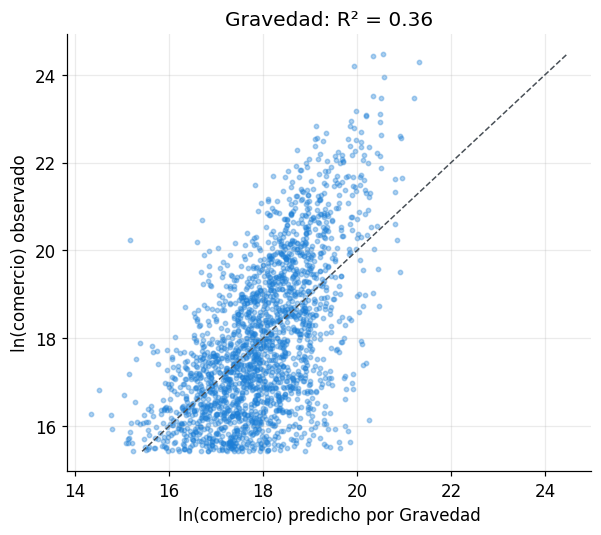

In [44]:
fig, ax = plt.subplots(figsize=(5.6, 5))
ax.scatter(pred, lw, s=8, alpha=.35, color=CFG)
lo, hi = lw.min(), lw.max(); ax.plot([lo, hi], [lo, hi], color="#495057", lw=1, ls="--")
ax.set(xlabel="ln(comercio) predicho por Gravedad", ylabel="ln(comercio) observado",
       title=f"Gravedad: R² = {r2:.2f}")
plt.tight_layout(); plt.savefig("figs/B2_gravedad.png", dpi=200); plt.show()

### ¿Los residuos positivos coinciden con los bloques comerciales?
Esta es la pregunta de la slide 5. Para cada arista decidimos si **ambos países pertenecen al mismo bloque**: UE-27, USMCA, Mercosur, RCEP. Comparamos el residuo medio dentro del bloque con el de las aristas fuera de él. Un **test de permutación** (5.000 mezclas) nos dice si la diferencia puede ser casualidad.

In [45]:
BLOQUES = {
 "UE-27": "AUT BEL BGR HRV CYP CZE DNK EST FIN FRA DEU GRC HUN IRL ITA LVA LTU LUX MLT NLD POL PRT ROU SVK SVN ESP SWE".split(),
 "USMCA": "USA CAN MEX".split(),
 "Mercosur": "ARG BRA PRY URY".split(),
 "RCEP": "AUS BRN KHM CHN IDN JPN KOR LAO MYS MMR NZL PHL SGP THA VNM".split()}
filas = []
for b, mi in BLOQUES.items():
    S = set(mi)
    intra = np.array([(V[i] in S) and (V[j] in S) for i, j in zip(ei, ej)])
    if intra.sum() == 0: continue
    dif = res[intra].mean() - res[~intra].mean()
    perm = np.array([(lambda p: res[p].mean() - res[~p].mean())(rng.permutation(intra)) for _ in range(5000)])
    filas.append({"bloque": b, "aristas_internas": int(intra.sum()), "residuo_medio_interno": res[intra].mean(),
                  "residuo_medio_externo": res[~intra].mean(), "diferencia": dif,
                  "factor_x": float(np.exp(dif)), "p_perm": float((np.abs(perm) >= abs(dif)).mean())})
bl = pd.DataFrame(filas).round(3); RES["B_bloques"] = bl.to_dict("records"); bl

,bloque,aristas_internas,residuo_medio_interno,residuo_medio_externo,diferencia,factor_x,p_perm
0,UE-27,401,0.268,-0.063,0.331,1.392,0.000
1,USMCA,6,2.371,-0.007,2.377,10.778,0.000
2,Mercosur,4,1.618,-0.003,1.621,5.060,0.022
3,RCEP,84,0.114,-0.005,0.118,1.126,0.451


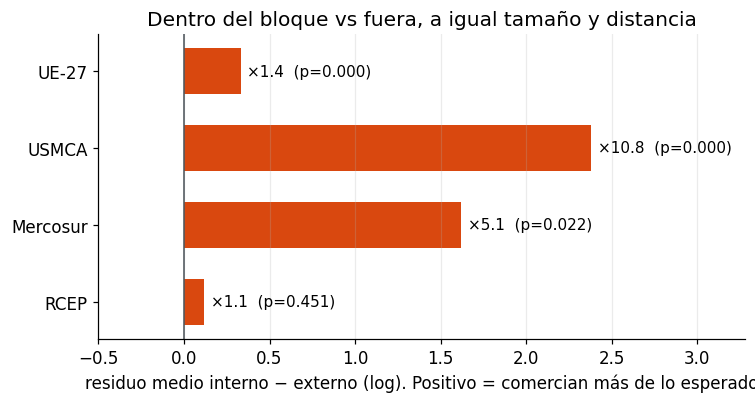

In [46]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.barh(bl["bloque"][::-1], bl["diferencia"][::-1], color=[REAL if d > 0 else ER for d in bl["diferencia"][::-1]], height=.6)
ax.axvline(0, color="#495057", lw=1)
for i, (d, f, p) in enumerate(zip(bl["diferencia"][::-1], bl["factor_x"][::-1], bl["p_perm"][::-1])):
    ax.text(d + (0.04 if d >= 0 else -0.04), i, f"×{f:.1f}  (p={p:.3f})", va="center", ha="left" if d >= 0 else "right", fontsize=10)
ax.set(xlabel="residuo medio interno − externo (log). Positivo = comercian más de lo esperado",
       title="Dentro del bloque vs fuera, a igual tamaño y distancia")
ax.set_xlim(min(-0.5, bl["diferencia"].min()-0.6), bl["diferencia"].max()+0.9); ax.grid(axis="y", alpha=0)
plt.tight_layout(); plt.savefig("figs/B3_bloques.png", dpi=200); plt.show()

In [47]:
top = pd.DataFrame({"origen": [V[i] for i in ei], "destino": [V[j] for j in ej], "USD_M": W[ei, ej]/1e6,
                    "km": D[ei, ej], "residuo": res, "veces_lo_esperado": np.exp(res)})
mas = top.sort_values("residuo", ascending=False).head(8).round(2)
menos = top.sort_values("residuo").head(8).round(2)
RES["B_res_top"] = mas.to_dict("records"); RES["B_res_bottom"] = menos.to_dict("records")
print("Comercian MUCHO MÁS de lo esperado:"); display(mas)
print("Comercian MUCHO MENOS de lo esperado:"); display(menos)

Comercian MUCHO MÁS de lo esperado:


,origen,destino,USD_M,km,residuo,veces_lo_esperado
768,GEO,KGZ,617.92,2442.64,5.08,160.13
1214,KOR,USA,32705.12,11170.04,4.28,72.02
1070,JPN,USA,41055.66,10903.84,4.11,60.88
1182,KOR,KGZ,972.41,4413.40,4.00,54.66
1366,MEX,USA,42237.69,3031.00,3.92,50.16
1006,JPN,AUS,8209.00,7948.91,3.71,40.80
232,CHN,KGZ,2178.34,3451.63,3.67,39.37
767,GEO,KAZ,591.86,2279.74,3.60,36.66


Comercian MUCHO MENOS de lo esperado:


,origen,destino,USD_M,km,residuo,veces_lo_esperado
1879,TUR,USA,6.25,8709.36,-4.19,0.02
1451,NOR,USA,5.42,6232.90,-4.13,0.02
118,BRA,USA,10.23,6790.79,-4.11,0.02
2036,IDN,USA,6.18,16359.23,-3.98,0.02
1438,NOR,GBR,5.49,1153.88,-3.91,0.02
1585,SAU,CHN,8.04,6588.87,-3.90,0.02
1586,SAU,DEU,5.61,4168.50,-3.80,0.02
1841,TUR,CHN,9.00,6865.28,-3.74,0.02


## 6. Mensajes para la presentación
1. **ER no sirve** como explicación. Configuración reproduce el clustering: los triángulos vienen de los hubs.
2. **El tamaño económico explica a quién se le vende** (grado de entrada), pero no *quién exporta autos* (grado de salida). Exportar autos depende de tener industria automotriz.
3. **Gravedad** captura una parte grande de la variación en montos. Los residuos muestran dónde importa algo más que tamaño y distancia.
4. Los **bloques comerciales** se evalúan con residuos, no con la topología binaria.

In [48]:
json.dump(RES, open("resultados.json", "w"), indent=1, default=float)
print("resultados.json guardado")

resultados.json guardado
